# Phân tích pilot DQN — Connect Four 7×6

Notebook đọc trực tiếp CSV do `train_dqn.py` sinh. Các số liệu là pilot 200 episode chạy CPU ngày 13/11/2026, không phải kết quả cuối.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

logs = sorted(Path('../results/logs').glob('train_dqn_*.csv'))
assert logs, 'Chua co train_dqn log'
df = pd.read_csv(logs[-1])
df.head()

,episode,opponent,agent_player,result,reward,moves,dqn_moves,epsilon,mean_loss,optimizer_updates,replay_size,elapsed_seconds,seed,device
0,1,heuristic,1,loss,-1.0,16,8,1.000000,0.0,0,8,0.003755,42,cpu
1,2,heuristic,2,loss,-1.0,7,3,0.999500,0.0,0,11,0.001090,42,cpu
2,3,heuristic,1,loss,-1.0,10,5,0.999000,0.0,0,16,0.001501,42,cpu
3,4,heuristic,2,loss,-1.0,15,7,0.998501,0.0,0,23,0.002519,42,cpu
4,5,heuristic,1,loss,-1.0,12,6,0.998001,0.0,0,29,0.001630,42,cpu


In [2]:
summary = {
    'episodes': len(df),
    'wins': int((df.result == 'win').sum()),
    'draws': int((df.result == 'draw').sum()),
    'losses': int((df.result == 'loss').sum()),
    'mean_reward': float(df.reward.mean()),
    'mean_huber_loss': float(df.mean_loss.mean()),
    'optimizer_updates': int(df.optimizer_updates.iloc[-1]),
    'final_epsilon': float(df.epsilon.iloc[-1]),
    'device': str(df.device.iloc[-1]),
}
summary

{'episodes': 200,
 'wins': 1,
 'draws': 0,
 'losses': 199,
 'mean_reward': -0.99,
 'mean_huber_loss': 0.004874197963158494,
 'optimizer_updates': 757,
 'final_epsilon': 0.905267423552102,
 'device': 'cpu'}

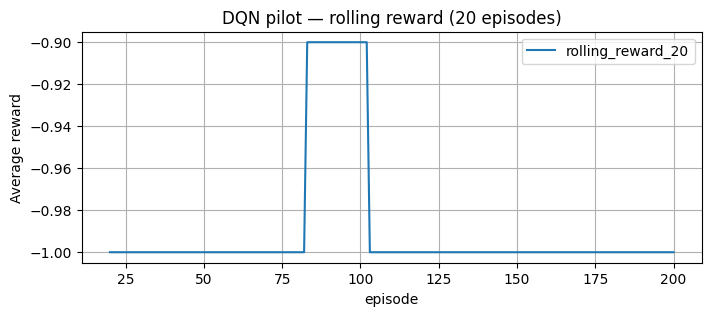

In [3]:
df['rolling_reward_20'] = df.reward.rolling(20).mean()
ax = df.plot(x='episode', y='rolling_reward_20', figsize=(8, 3), grid=True, title='DQN pilot — rolling reward (20 episodes)')
ax.set_ylabel('Average reward')
plt.show()

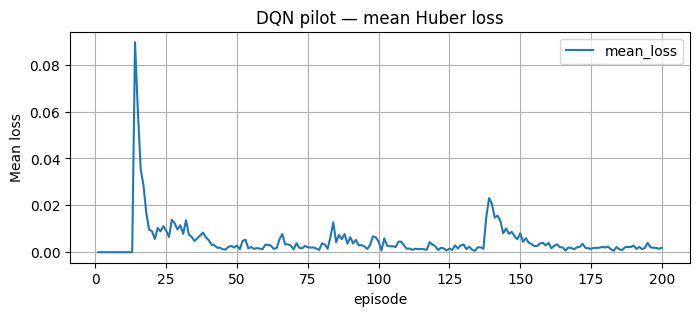

In [4]:
ax = df.plot(x='episode', y='mean_loss', figsize=(8, 3), grid=True, title='DQN pilot — mean Huber loss')
ax.set_ylabel('Mean loss')
plt.show()

## Diễn giải

Với 200 episode, DQN mới có 1 chiến thắng và 199 thất bại trước Heuristic trong tập huấn luyện; epsilon cuối vẫn xấp xỉ 0,905. Loss giảm không thể tự nó chứng minh chính sách đã học tốt. Cần chạy các checkpoint 1.000–10.000 episode và đánh giá riêng trên validation theo kế hoạch A4.